# 04 - Optimization & Final Evaluation



- _1_ Tune the two candidates (Logistic Regression, Gradient Boosting) on the training set.
- _2_ Compare the tuned models with the same 5 folds.
- _3_ Choose and freeze the final model.
- _4_ Open the test set **once** and evaluate the final model.
- _5_ Analyze the errors and the limits.
- _6_ Save the complete pipeline (preprocessing + model).



In [1]:
import platform
import sys
from datetime import datetime
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
import sklearn
from sklearn.inspection import permutation_importance
from sklearn.metrics import ConfusionMatrixDisplay, RocCurveDisplay, classification_report, confusion_matrix
from sklearn.model_selection import GridSearchCV, RandomizedSearchCV, cross_validate

# Allow importing src/ when the notebook is opened from notebooks/
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'src').exists())
sys.path.insert(0, str(ROOT))

from src import config
from src.evaluation import compute_metrics, save_json
from src.models import PARAM_GRIDS, SCORING, get_cv, get_models
from src.preprocessing import MODEL_FEATURES, build_model_pipeline, prepare_features, prepare_target

sns.set_theme(style='whitegrid')
pd.set_option('display.max_columns', 50)
REPORTS = config.ROOT / 'reports'

## [_1_] Load the training set & the Step 3 results

In [2]:
train = pd.read_csv(config.DATA_INTERIM / 'train.csv')
X_train = prepare_features(train)
y_train = prepare_target(train)

cv = get_cv()          
models = get_models() 

print('X_train shape:', X_train.shape)

step3_results = pd.read_csv(REPORTS / '03_cv_results.csv', index_col='model')
step3_results.round(3)

X_train shape: (1600, 15)


,accuracy,precision_macro,recall_macro,f1_macro,f1_weighted,roc_auc_ovr,f1_macro_std,fit_time_s
model,,,,,,,,
Logistic Regression,0.752,0.752,0.751,0.751,0.752,0.906,0.022,0.124
Gradient Boosting,0.683,0.684,0.682,0.683,0.684,0.857,0.015,1.787
Random Forest,0.669,0.662,0.668,0.663,0.664,0.849,0.021,1.108
Dummy (baseline),0.339,0.339,0.339,0.339,0.339,0.504,0.025,0.062


## [_2_] Tune Logistic Regression (GridSearchCV)

12 combinations x 5 folds = 60 fits. Every combination is tested.
- `C`: small values = stronger regularization = simpler model.
- `class_weight`: no correction vs balanced weights (decision from Step 2).

In [4]:
lr_search = GridSearchCV(
    estimator=build_model_pipeline(models['Logistic Regression']),
    param_grid=PARAM_GRIDS['Logistic Regression'],
    scoring='f1_macro',
    cv=cv,
    n_jobs=-1,
)
lr_search.fit(X_train, y_train)

print('Best parameters:', lr_search.best_params_)
print('Best CV macro F1:', round(lr_search.best_score_, 3))

Best parameters: {'model__C': 10, 'model__class_weight': 'balanced'}
Best CV macro F1: 0.752


In [5]:
lr_results = pd.DataFrame(lr_search.cv_results_)
lr_results['C'] = lr_results['param_model__C'].astype(float)
lr_results['class_weight'] = lr_results['param_model__class_weight'].astype(str)

lr_table = lr_results[['C', 'class_weight', 'mean_test_score', 'std_test_score', 'rank_test_score']]
lr_table.sort_values('rank_test_score').round(4)

,C,class_weight,mean_test_score,std_test_score,rank_test_score
11,100.000,balanced,0.7517,0.0199,1
9,10.000,balanced,0.7517,0.0199,1
7,1.000,balanced,0.7511,0.0232,3
6,1.000,NaN,0.7511,0.0220,4
10,100.000,NaN,0.7507,0.0218,5
8,10.000,NaN,0.7507,0.0218,5
5,0.100,balanced,0.7478,0.0186,7
4,0.100,NaN,0.7473,0.0174,8
3,0.010,balanced,0.7010,0.0194,9
2,0.010,NaN,0.7002,0.0203,10


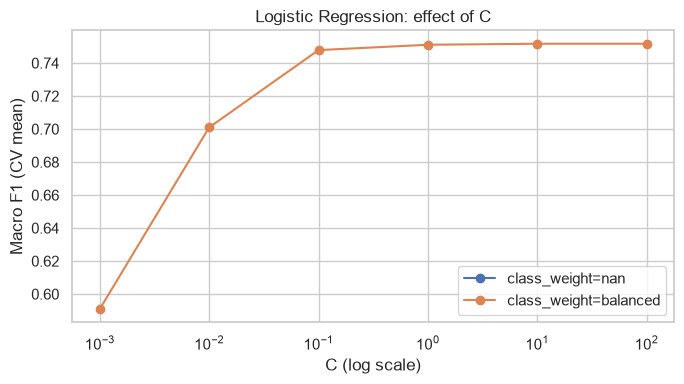

In [6]:
plt.figure(figsize=(7, 4))
for weight in lr_results['class_weight'].unique():
    subset = lr_results[lr_results['class_weight'] == weight].sort_values('C')
    plt.semilogx(subset['C'], subset['mean_test_score'], marker='o', label=f'class_weight={weight}')

plt.xlabel('C (log scale)')
plt.ylabel('Macro F1 (CV mean)')
plt.title('Logistic Regression: effect of C')
plt.legend()
plt.tight_layout()
plt.savefig(config.FIGURES / '04_lr_tuning.png', dpi=120)
plt.show()

## [_3_] Tune Gradient Boosting (RandomizedSearchCV)

The full grid has 576 combinations. 25 random combinations are tested to keep the run time short (a few minutes).

In [7]:
gb_search = RandomizedSearchCV(
    estimator=build_model_pipeline(models['Gradient Boosting']),
    param_distributions=PARAM_GRIDS['Gradient Boosting'],
    n_iter=25,
    scoring='f1_macro',
    cv=cv,
    random_state=config.RANDOM_STATE,
    n_jobs=-1,
)
gb_search.fit(X_train, y_train)

print('Best parameters:', gb_search.best_params_)
print('Best CV macro F1:', round(gb_search.best_score_, 3))

Best parameters: {'model__subsample': 0.7, 'model__n_estimators': 300, 'model__min_samples_leaf': 5, 'model__max_depth': 3, 'model__learning_rate': 0.05}
Best CV macro F1: 0.704


In [8]:
gb_results = pd.DataFrame(gb_search.cv_results_)
param_columns = [c for c in gb_results.columns if c.startswith('param_')]

gb_table = gb_results[param_columns + ['mean_test_score', 'std_test_score', 'rank_test_score']]
gb_table.sort_values('rank_test_score').head(10).round(4)

,param_model__subsample,param_model__n_estimators,param_model__min_samples_leaf,param_model__max_depth,param_model__learning_rate,mean_test_score,std_test_score,rank_test_score
4,0.70,300,5,3,0.05,0.7038,0.0214,1
3,0.70,300,5,2,0.10,0.6989,0.0084,2
22,0.70,500,5,3,0.05,0.6987,0.0254,3
2,0.85,500,1,2,0.05,0.6975,0.0169,4
5,0.85,200,5,3,0.05,0.6974,0.0289,5
6,0.85,300,5,3,0.03,0.6925,0.0301,6
18,1.00,300,20,2,0.10,0.6919,0.0113,7
9,1.00,300,20,2,0.05,0.6898,0.0111,8
20,0.85,100,20,3,0.10,0.6897,0.0154,9
12,1.00,200,20,3,0.03,0.6881,0.0313,10


## [_4_] Compare tuned and default models

The tuned pipelines are scored again with the same folds to get all metrics.

Note: the best tuned score is slightly optimistic because it is the best of many tries. The test set will give the honest estimate.

In [9]:
tuned_models = {
    'Logistic Regression (tuned)': lr_search.best_estimator_,
    'Gradient Boosting (tuned)': gb_search.best_estimator_,
}

rows = []
for name, pipeline in tuned_models.items():
    scores = cross_validate(pipeline, X_train, y_train, cv=cv, scoring=SCORING)
    row = {'model': name}
    for metric in SCORING:
        row[metric] = scores[f'test_{metric}'].mean()
    row['f1_macro_std'] = scores['test_f1_macro'].std()
    row['fit_time_s'] = scores['fit_time'].mean()
    rows.append(row)

tuned_results = pd.DataFrame(rows).set_index('model')

comparison = pd.concat([step3_results, tuned_results]).sort_values('f1_macro', ascending=False)
comparison.round(4).to_csv(REPORTS / '04_tuned_results.csv')
comparison.round(3)

,accuracy,precision_macro,recall_macro,f1_macro,f1_weighted,roc_auc_ovr,f1_macro_std,fit_time_s
model,,,,,,,,
Logistic Regression (tuned),0.752,0.753,0.751,0.752,0.752,0.906,0.020,0.105
Logistic Regression,0.752,0.752,0.751,0.751,0.752,0.906,0.022,0.124
Gradient Boosting (tuned),0.704,0.705,0.704,0.704,0.705,0.871,0.021,3.879
Gradient Boosting,0.683,0.684,0.682,0.683,0.684,0.857,0.015,1.787
Random Forest,0.669,0.662,0.668,0.663,0.664,0.849,0.021,1.108
Dummy (baseline),0.339,0.339,0.339,0.339,0.339,0.504,0.025,0.062


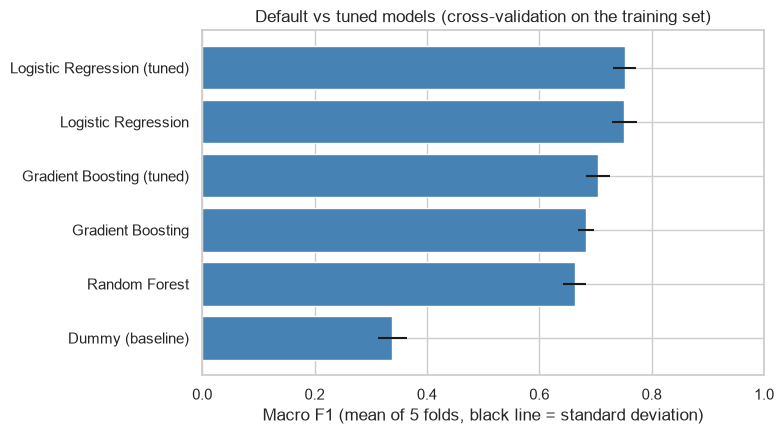

In [10]:
plot_data = comparison.sort_values('f1_macro')

plt.figure(figsize=(8, 4.5))
plt.barh(plot_data.index, plot_data['f1_macro'], xerr=plot_data['f1_macro_std'], color='steelblue')
plt.xlim(0, 1)
plt.xlabel('Macro F1 (mean of 5 folds, black line = standard deviation)')
plt.title('Default vs tuned models (cross-validation on the training set)')
plt.tight_layout()
plt.savefig(config.FIGURES / '04_tuned_comparison.png', dpi=120)
plt.show()

## [_5_] Choose and freeze the final model

Rule: Gradient Boosting is chosen only if it beats Logistic Regression by **more than one standard deviation**. Otherwise the simpler, faster and more interpretable model is kept.

`best_estimator_` has already been refitted on the **whole training set** with the best parameters.

In [11]:
lr_f1 = tuned_results.loc['Logistic Regression (tuned)', 'f1_macro']
gb_f1 = tuned_results.loc['Gradient Boosting (tuned)', 'f1_macro']
gb_std = tuned_results.loc['Gradient Boosting (tuned)', 'f1_macro_std']

print(f'Tuned Logistic Regression macro F1: {lr_f1:.3f}')
print(f'Tuned Gradient Boosting macro F1:   {gb_f1:.3f} (std {gb_std:.3f})')

if gb_f1 - lr_f1 > gb_std:
    final_name = 'Gradient Boosting (tuned)'
    final_search = gb_search
else:
    final_name = 'Logistic Regression (tuned)'
    final_search = lr_search

final_pipeline = final_search.best_estimator_

print('\nFinal model:', final_name)
print('Parameters:', final_search.best_params_)

Tuned Logistic Regression macro F1: 0.752
Tuned Gradient Boosting macro F1:   0.704 (std 0.021)

Final model: Logistic Regression (tuned)
Parameters: {'model__C': 10, 'model__class_weight': 'balanced'}


## [_6_] Final evaluation on the independent test set

The test set is opened **here for the first time**. The model is already frozen.

In [ ]:
test = pd.read_csv(config.DATA_INTERIM / 'test.csv')
X_test = prepare_features(test)
y_test = prepare_target(test)

# The fitted pipeline only transforms the test data => nothing is refitted
y_pred = final_pipeline.predict(X_test)
y_proba = final_pipeline.predict_proba(X_test)

print('X_test shape:', X_test.shape)

X_test shape: (400, 15)


In [13]:
test_metrics = compute_metrics(y_test, y_pred, y_proba, final_pipeline.classes_)
cv_metrics = {m: round(float(tuned_results.loc[final_name, m]), 4) for m in SCORING}

cv_vs_test = pd.DataFrame({'cross_validation (train)': cv_metrics, 'test': test_metrics})
cv_vs_test['difference'] = cv_vs_test['test'] - cv_vs_test['cross_validation (train)']
cv_vs_test.round(3)

,cross_validation (train),test,difference
accuracy,0.752,0.755,0.003
precision_macro,0.753,0.756,0.002
recall_macro,0.751,0.754,0.003
f1_macro,0.752,0.755,0.003
f1_weighted,0.752,0.756,0.003
roc_auc_ovr,0.906,0.914,0.009


In [14]:
print(classification_report(y_test, y_pred, labels=config.TARGET_ORDER, digits=3))

              precision    recall  f1-score   support

         Low      0.822     0.803     0.812       132
      Medium      0.630     0.644     0.637       132
        High      0.816     0.816     0.816       136

    accuracy                          0.755       400
   macro avg      0.756     0.754     0.755       400
weighted avg      0.756     0.755     0.756       400



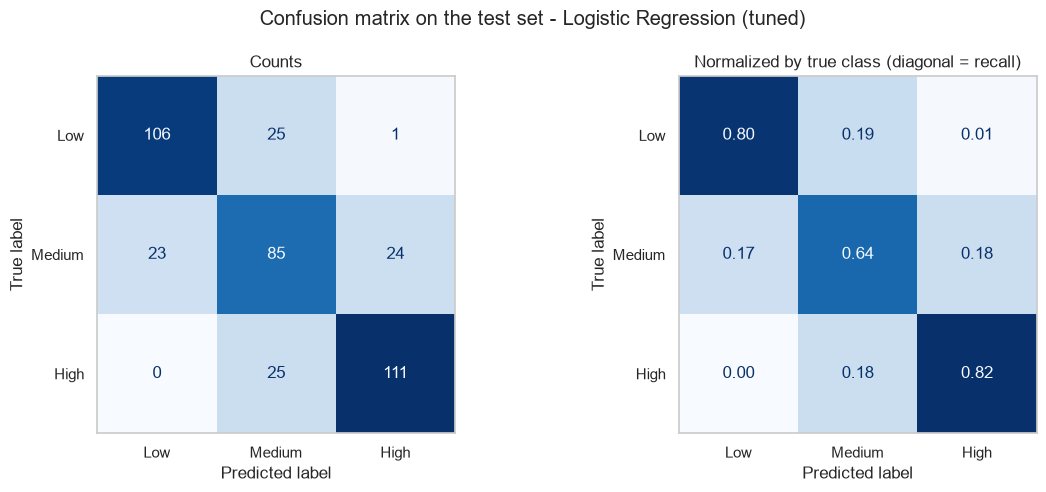

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred, labels=config.TARGET_ORDER, cmap='Blues', colorbar=False, ax=axes[0]
)
axes[0].set_title('Counts')

ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred, labels=config.TARGET_ORDER, normalize='true',
    values_format='.2f', cmap='Blues', colorbar=False, ax=axes[1]
)
axes[1].set_title('Normalized by true class (diagonal = recall)')

for ax in axes:
    ax.grid(False)

plt.suptitle(f'Confusion matrix on the test set - {final_name}')
plt.tight_layout()
plt.savefig(config.FIGURES / '04_test_confusion_matrix.png', dpi=120)
plt.show()

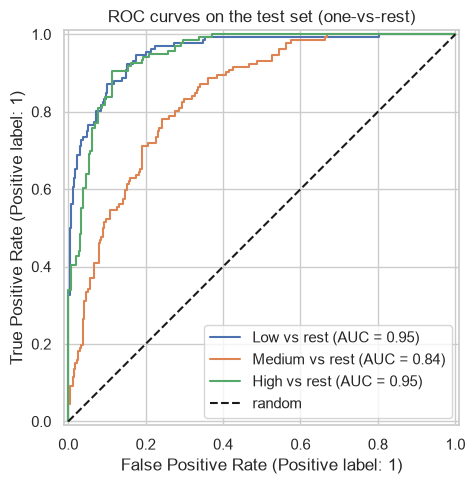

In [16]:
# One ROC curve per class: this class vs the two others
class_list = list(final_pipeline.classes_)

fig, ax = plt.subplots(figsize=(6, 5))
for cls in config.TARGET_ORDER:
    column = class_list.index(cls)
    RocCurveDisplay.from_predictions(y_test == cls, y_proba[:, column], name=f'{cls} vs rest', ax=ax)

ax.plot([0, 1], [0, 1], 'k--', label='random')
ax.set_title('ROC curves on the test set (one-vs-rest)')
ax.legend()
plt.tight_layout()
plt.savefig(config.FIGURES / '04_test_roc_curves.png', dpi=120)
plt.show()

## [_7_] Error analysis

- Are errors mostly between neighbouring classes or between the extremes?
- Which class is the hardest?


In [17]:
results_test = X_test.copy()
results_test['true'] = y_test.values
results_test['predicted'] = y_pred
results_test['confidence'] = y_proba.max(axis=1)
results_test['correct'] = results_test['true'] == results_test['predicted']

high_as_low = ((results_test['true'] == 'High') & (results_test['predicted'] == 'Low')).sum()
low_as_high = ((results_test['true'] == 'Low') & (results_test['predicted'] == 'High')).sum()

print('Total errors:', (~results_test['correct']).sum(), 'out of', len(results_test))
print('High predicted as Low:', high_as_low)
print('Low predicted as High:', low_as_high)

error_by_class = 1 - results_test.groupby('true')['correct'].mean().reindex(config.TARGET_ORDER)
error_by_class.round(3).to_frame('error_rate')

Total errors: 98 out of 400
High predicted as Low: 0
Low predicted as High: 1


,error_rate
true,
Low,0.197
Medium,0.356
High,0.184


## [_8_] Which features does the model use?

**Permutation importance**: shuffle one feature and measure how much macro F1 drops. It works for any model.

This is computed after the model is frozen and is used only to **explain** the model, not to change it. Importance means association in a synthetic dataset, not causation.

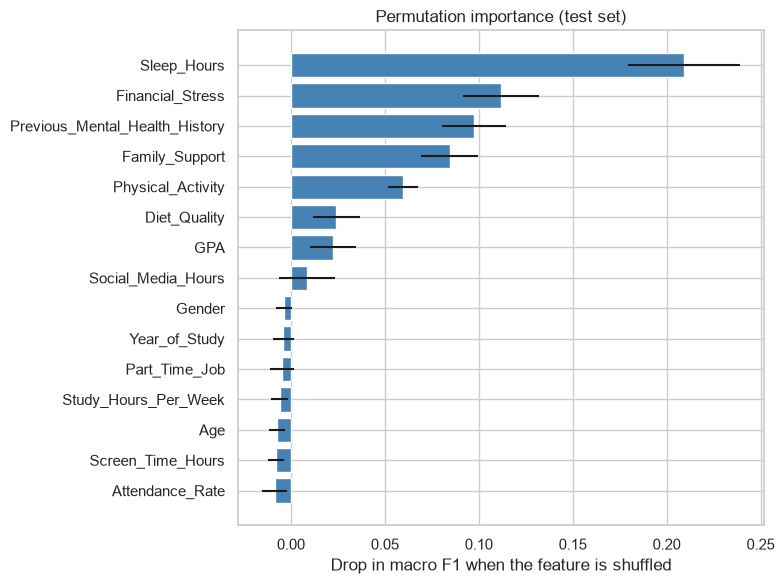

,importance_mean,importance_std
Sleep_Hours,0.2093,0.0297
Financial_Stress,0.1119,0.0202
Previous_Mental_Health_History,0.0973,0.0170
Family_Support,0.0845,0.0153
Physical_Activity,0.0595,0.0080
Diet_Quality,0.0242,0.0123
GPA,0.0224,0.0123
Social_Media_Hours,0.0085,0.0149
Gender,-0.0039,0.0043
Year_of_Study,-0.0041,0.0057


In [22]:
perm = permutation_importance(
    final_pipeline, X_test, y_test,
    scoring='f1_macro', n_repeats=10,
    random_state=config.RANDOM_STATE, n_jobs=-1,
)

importance = pd.DataFrame({
    'importance_mean': perm.importances_mean,
    'importance_std': perm.importances_std,
}, index=X_test.columns).sort_values('importance_mean')

plt.figure(figsize=(8, 6))
plt.barh(importance.index, importance['importance_mean'], xerr=importance['importance_std'], color='steelblue')
plt.xlabel('Drop in macro F1 when the feature is shuffled')
plt.title('Permutation importance (test set)')
plt.tight_layout()
plt.savefig(config.FIGURES / '04_permutation_importance.png', dpi=120)
plt.show()

importance.sort_values('importance_mean', ascending=False).round(4)

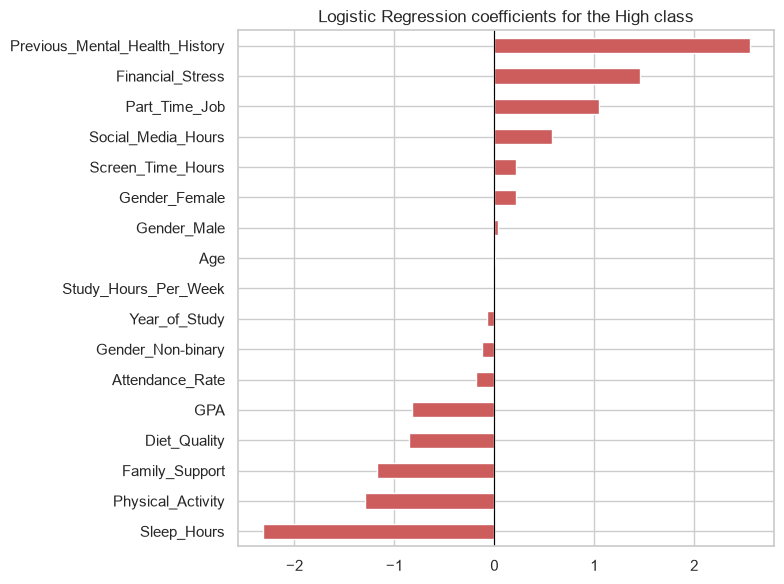

,Low,Medium,High
Sleep_Hours,2.275,0.045,-2.319
Physical_Activity,1.274,0.015,-1.289
Family_Support,1.149,0.028,-1.178
Diet_Quality,0.872,-0.021,-0.851
GPA,0.866,-0.046,-0.820
Attendance_Rate,0.125,0.062,-0.187
Gender_Non-binary,0.069,0.053,-0.122
Year_of_Study,0.026,0.045,-0.071
Study_Hours_Per_Week,0.099,-0.094,-0.005
Age,-0.043,0.037,0.006


In [ ]:

if final_name.startswith('Logistic Regression'):
    model = final_pipeline.named_steps['model']
    feature_names = final_pipeline.named_steps['preprocessor'].get_feature_names_out()

    coefs = pd.DataFrame(model.coef_.T, index=feature_names, columns=model.classes_)
    coefs = coefs[config.TARGET_ORDER].sort_values('High')

    coefs['High'].plot(kind='barh', figsize=(8, 6), color='indianred')
    plt.axvline(0, color='black', linewidth=0.8)
    plt.title('Logistic Regression coefficients for the High class')
    plt.tight_layout()
    plt.savefig(config.FIGURES / '04_lr_coefficients_high.png', dpi=120)
    plt.show()

    display(coefs.round(3))
else:
    print('Final model is not Logistic Regression: see permutation importance above.')

## [_9_] Save the complete pipeline and its metadata

The saved pipeline contains preprocessing + model, so it accepts **raw** student data.

In [24]:
model_path = config.MODELS / 'final_pipeline.joblib'
joblib.dump(final_pipeline, model_path)

metadata = {
    'model_name': final_name,
    'best_params': final_search.best_params_,
    'features': MODEL_FEATURES,
    'classes': config.TARGET_ORDER,
    'n_train': len(X_train),
    'n_test': len(X_test),
    'cv_metrics': cv_metrics,
    'test_metrics': test_metrics,
    'test_classification_report': classification_report(
        y_test, y_pred, labels=config.TARGET_ORDER, output_dict=True
    ),
    'test_confusion_matrix': confusion_matrix(y_test, y_pred, labels=config.TARGET_ORDER).tolist(),
    'versions': {
        'python': platform.python_version(),
        'scikit-learn': sklearn.__version__,
        'pandas': pd.__version__,
    },
    'dataset': 'Kaggle - maqdadali/mental-health-risk-prediction-dataset-students (synthetic)',
    'created_at': datetime.now().isoformat(timespec='seconds'),
    'warning': 'Pedagogical prototype. Not a diagnostic, screening or decision tool.',
}

metrics_path = REPORTS / 'final_metrics.json'
save_json(metadata, metrics_path)

print('Pipeline saved to:', model_path)
print('Metrics saved to: ', metrics_path)

Pipeline saved to: C:\Users\hamza\Desktop\dev_ai\CampusWell\models\final_pipeline.joblib
Metrics saved to:  C:\Users\hamza\Desktop\dev_ai\CampusWell\reports\final_metrics.json


In [ ]:

loaded_pipeline = joblib.load(model_path)

same_predictions = (loaded_pipeline.predict(X_test) == y_pred).all()
print('Same predictions after reload:', same_predictions)
assert same_predictions

Same predictions after reload: True


In [ ]:
# Example: a new fictional student with raw values & one missing value
new_student = pd.DataFrame([{
    'Age': 21,
    'Year_of_Study': 2,
    'Sleep_Hours': 5.5,
    'Study_Hours_Per_Week': 35,
    'GPA': 2.6,
    'Social_Media_Hours': 6.0,
    'Screen_Time_Hours': 9.0,
    'Financial_Stress': 8.0,
    'Family_Support': 4.0,
    'Attendance_Rate': 70,
    'Gender': 'Female',
    'Physical_Activity': 'Low',
    'Diet_Quality': None,
    'Part_Time_Job': 'Yes',
    'Previous_Mental_Health_History': 'No',
}])

prediction = loaded_pipeline.predict(new_student)[0]
probabilities = pd.Series(loaded_pipeline.predict_proba(new_student)[0], index=loaded_pipeline.classes_)

print('Predicted label (dataset label, not a diagnosis):', prediction)
print(probabilities.reindex(config.TARGET_ORDER).round(3))

Predicted label (dataset label, not a diagnosis): High
Low       0.0
Medium    0.0
High      1.0
dtype: float64
